In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:

import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:

# Cell 2: Install uv and prepare a separate Python 3.11 environment

%pip install -q uv

!uv python install 3.11
!uv venv --python 3.11 /kaggle/working/opennmt-env

print("Separate Python environment prepared.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 63.2 MB/s eta 0:00:00:00:0100:01
Note: you may need to restart the kernel to use updated packages.
Installed Python 3.11.17 in 1.15s
 + cpython-3.11.17-linux-x86_64-gnu (python3.11)
Using CPython 3.11.17
Creating virtual environment at: opennmt-env
Activate with: source opennmt-env/bin/activate
Separate Python environment prepared.


In [ ]:

# Cell 3: Install compatible PyTorch and OpenNMT-py

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

!uv pip install --python $ENV_PY \
    torch==2.2.2 \
    --index-url https://download.pytorch.org/whl/cu121

!uv pip install --python $ENV_PY \
    "OpenNMT-py==3.5.1" \
    datasets sacrebleu sentencepiece


Using Python 3.11.17 environment at: opennmt-env
Resolved 22 packages in 847ms                                        
Prepared 22 packages in 28.64s                                           
░░░░░░░░░░░░░░░░░░░░ [0/22] Installing wheels...                                warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 22 packages in 4.71s                              
 + filelock==3.32.3
 + fsspec==2026.7.0
 + jinja2==3.1.6
 + markupsafe==3.0.3
 + mpmath==1.3.0
 + networkx==3.6.1
 + nvidia-cublas-cu12==12.1.3.1
 + nvidia-cuda-cupti-cu12==12.1.105
 + nvidia-cuda-nvrtc-cu12==12.1.105
 + nvidia-cuda-runtime-cu12==12.1.105
 + nvidia-cudnn-cu12==8.9.2.26
 + nvidia-cufft-cu12==11.0.2.54
 + nvidia-curand-cu12

In [ ]:

# Cell 4: Verify the isolated environment

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import sys
import torch
import sacrebleu
import datasets
import onmt

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("SacreBLEU:", sacrebleu.__version__)
print("OpenNMT-py imported successfully.")
"""

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Environment verification failed.")

print("Environment verified successfully.")


Python: 3.11.17 (main, Oct 14 2026, 01:05:33) [Clang 23.1.3 ]
PyTorch: 2.2.2+cu121
CUDA available: True
SacreBLEU: 2.6.0
OpenNMT-py imported successfully.

Environment verified successfully.


In [ ]:
import os
import subprocess
from kaggle_secrets import UserSecretsClient

# Get the token securely from Kaggle Secrets
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import os
from huggingface_hub import HfApi

api = HfApi(token=os.environ["HF_TOKEN"])
info = api.dataset_info("ai4bharat/BPCC")

print("Dataset:", info.id)
print("Dataset access verified.")
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset access failed.")

Dataset: ai4bharat/BPCC
Dataset access verified.



In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

inspect_code = """
import os
from huggingface_hub import HfApi

api = HfApi(token=os.environ["HF_TOKEN"])

info = api.dataset_info("ai4bharat/BPCC")
print("Dataset:", info.id)
print("\\nAvailable dataset files:")

files = api.list_repo_files(
    "ai4bharat/BPCC",
    repo_type="dataset"
)

for f in files[:60]:
    print(f)

if len(files) > 60:
    print(f"... and {len(files) - 60} more files")
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", inspect_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Could not inspect the dataset.")


Dataset: ai4bharat/BPCC

Available dataset files:
.gitattributes
BPCC-seed.zip
README.md
additional/.gitattributes
additional/BPCC.zip
additional/IN22_testset.zip
additional/en-indic-dist.tar.gz
additional/en-indic-fairseq-dict.zip
additional/en-indic-preprint.tar.gz
additional/en-indic-spm.zip
additional/flores-22_dev.zip
additional/indic-en-dist.tar.gz
additional/indic-en-fairseq-dict.zip
additional/indic-en-preprint.tar.gz
additional/indic-en-spm.zip
additional/indic-indic-fairseq-dict.zip
additional/indic-indic-spm.zip
additional/translation_outputs.tar.gz
bpcc-seed-latest/asm_Beng.tsv
bpcc-seed-latest/ben_Beng.tsv
bpcc-seed-latest/brx_Deva.tsv
bpcc-seed-latest/doi_Deva.tsv
bpcc-seed-latest/gom_Deva.tsv
bpcc-seed-latest/guj_Gujr.tsv
bpcc-seed-latest/hin_Deva.tsv
bpcc-seed-latest/kan_Knda.tsv
bpcc-seed-latest/kas_Arab.tsv
bpcc-seed-latest/mai_Deva.tsv
bpcc-seed-latest/mal_Mlym.tsv
bpcc-seed-latest/mar_Deva.tsv
bpcc-seed-latest/mni_Mtei.tsv
bpcc-seed-latest/npi_Deva.tsv
bpcc-seed-lat

In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

inspect_code = """
import os
from huggingface_hub import HfApi

api = HfApi(token=os.environ["HF_TOKEN"])

files = api.list_repo_files(
    "ai4bharat/BPCC",
    repo_type="dataset"
)

print("English-Hindi files:")
for f in files:
    if "eng_Latn-hin_Deva" in f:
        print(f)

print("\\nHindi seed files:")
for f in files:
    if "bpcc-seed-latest/hin_Deva" in f or "bpcc-seed-v1/hin_Deva" in f:
        print(f)
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", inspect_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("File inspection failed.")


English-Hindi files:
bpcc-seed-v1/eng_Latn-hin_Deva/domain.txt
comparable/eng_Latn-hin_Deva/labse_scores.txt
nllb_filtered/eng_Latn-hin_Deva/labse_scores.txt
samanantar_v0.3_filtered/eng_Latn-hin_Deva/labse_scores.txt
samanantar_v2/eng_Latn-hin_Deva/labse_scores.txt
wiki/eng_Latn-hin_Deva/domain.txt

Hindi seed files:
bpcc-seed-latest/hin_Deva.tsv
bpcc-seed-v1/hin_Deva.tsv



In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

inspect_code = """
import os
from huggingface_hub import hf_hub_download

repo = "ai4bharat/BPCC"
token = os.environ["HF_TOKEN"]

# Inspect dataset documentation
readme_path = hf_hub_download(
    repo_id=repo,
    filename="README.md",
    repo_type="dataset",
    token=token
)

print("===== README (first 180 lines) =====")
with open(readme_path, encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i >= 180:
            break
        print(line.rstrip())

# Inspect the Hindi seed TSV structure
for filename in [
    "bpcc-seed-latest/hin_Deva.tsv",
    "bpcc-seed-v1/hin_Deva.tsv"
]:
    try:
        path = hf_hub_download(
            repo_id=repo,
            filename=filename,
            repo_type="dataset",
            token=token
        )
        print("\\n=====", filename, "=====")
        with open(path, encoding="utf-8") as f:
            for i, line in enumerate(f):
                if i >= 5:
                    break
                print(repr(line.rstrip("\\n")))
    except Exception as e:
        print("Could not inspect", filename, ":", str(e))
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", inspect_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset inspection failed.")


===== README (first 180 lines) =====
---
configs:
- config_name: bpcc-seed-latest
  data_files:
  - split: asm_Beng
    path: "bpcc-seed-latest/asm_Beng.tsv"
  - split: ben_Beng
    path: "bpcc-seed-latest/ben_Beng.tsv"
  - split: brx_Deva
    path: "bpcc-seed-latest/brx_Deva.tsv"
  - split: doi_Deva
    path: "bpcc-seed-latest/doi_Deva.tsv"
  - split: gom_Deva
    path: "bpcc-seed-latest/gom_Deva.tsv"
  - split: guj_Gujr
    path: "bpcc-seed-latest/guj_Gujr.tsv"
  - split: hin_Deva
    path: "bpcc-seed-latest/hin_Deva.tsv"
  - split: kan_Knda
    path: "bpcc-seed-latest/kan_Knda.tsv"
  - split: kas_Arab
    path: "bpcc-seed-latest/kas_Arab.tsv"
  - split: mai_Deva
    path: "bpcc-seed-latest/mai_Deva.tsv"
  - split: mal_Mlym
    path: "bpcc-seed-latest/mal_Mlym.tsv"
  - split: mar_Deva
    path: "bpcc-seed-latest/mar_Deva.tsv"
  - split: mni_Mtei
    path: "bpcc-seed-latest/mni_Mtei.tsv"
  - split: npi_Deva
    path: "bpcc-seed-latest/npi_Deva.tsv"
  - split: ory_Orya
    path: "bpcc-

In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

load_code = """
import os
import pandas as pd
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="ai4bharat/BPCC",
    filename="bpcc-seed-latest/hin_Deva.tsv",
    repo_type="dataset",
    token=os.environ["HF_TOKEN"]
)

df = pd.read_csv(path, sep="\\\\t")

print("Columns:", df.columns.tolist())
print("Original rows:", len(df))

df = df[["src", "tgt"]].dropna()
df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()

df = df[(df["src"] != "") & (df["tgt"] != "")]
df = df.drop_duplicates(subset=["src", "tgt"]).reset_index(drop=True)

print("Clean rows:", len(df))
print("\\\\nSample English-Hindi pairs:")
for i, row in df.head(5).iterrows():
    print(f"\\\\n{i + 1}. EN: {row['src']}")
    print(f"   HI: {row['tgt']}")
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", load_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Could not load the BPCC TSV.")


Columns: ['tgt', 'src', 'src_lang', 'tgt_lang']
Original rows: 99722
Clean rows: 96233
\nSample English-Hindi pairs:
\n1. EN: A member of the British East India Company enjoying a Durbar.
   HI: दरबार का आनंद लेते हुए ब्रिटिश ईस्ट इंडिया कंपनी का एक सदस्य।
\n2. EN: """It was the greatest source of encouragement for me,"" Tendulkar said nearly 20 years later after surpassing Gavaskar's world record of 34 Test centuries."
   HI: तेंदुलकर ने गावस्कर के 34 टेस्ट शतकों के विश्व रिकॉर्ड को तोड़ने के लगभग 20 वर्षों बाद कहा, कि यह उनके लिए सबसे बड़ा प्रोत्साहन का स्रोत था।
\n3. EN: Jahanara, certainly, interceded at various times on behalf of all of the princes and was well-regarded by Aurangzeb even though she shared the religious outlook of Dara.
   HI: निस्संदेह जहाँआरा सभी राजकुमारों की ओर से विभिन्न समय पर मध्यस्थता करती थीं और औरंगजेब द्वारा भली-भाँति सम्मानित थीं, भले ही वे धार्मिक दृष्टिकोण दारा का साझा करती थीं।
\n4. EN: As Gandhi embarked on the Dandi Salt March, Patel was arrested i

In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

bin_code = """
import pandas as pd
from huggingface_hub import hf_hub_download
import os

path = hf_hub_download(
    repo_id="ai4bharat/BPCC",
    filename="bpcc-seed-latest/hin_Deva.tsv",
    repo_type="dataset",
    token=os.environ["HF_TOKEN"]
)

df = pd.read_csv(path, sep="\\\\t")
df = df[["src", "tgt"]].dropna().copy()

df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()

df = df[(df["src"] != "") & (df["tgt"] != "")]
df = df.drop_duplicates(subset=["src", "tgt"]).reset_index(drop=True)

# Count English words
df["src_length"] = df["src"].apply(lambda s: len(s.split()))

# Assign bins
def length_bin(n):
    if n <= 10:
        return "Bin 1 (<=10)"
    elif n < 20:
        return "Bin 2 (11-19)"
    elif n < 30:
        return "Bin 3 (20-29)"
    else:
        return "Bin 4 (>=30)"

df["length_bin"] = df["src_length"].apply(length_bin)

print("Total clean pairs:", len(df))
print("\\\\nSentence-length distribution:")
print(df["length_bin"].value_counts().reindex([
    "Bin 1 (<=10)",
    "Bin 2 (11-19)",
    "Bin 3 (20-29)",
    "Bin 4 (>=30)"
]).fillna(0).astype(int))

print("\\\\nLength statistics:")
print(df["src_length"].describe())
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", bin_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Sentence-length binning failed.")


Total clean pairs: 96233
\nSentence-length distribution:
length_bin
Bin 1 (<=10)     13373
Bin 2 (11-19)    59480
Bin 3 (20-29)    22699
Bin 4 (>=30)       681
Name: count, dtype: int64
\nLength statistics:
count    96233.000000
mean        15.700934
std          5.576398
min          1.000000
25%         12.000000
50%         14.000000
75%         19.000000
max         84.000000
Name: src_length, dtype: float64



In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", ENV_PY,
        "scikit-learn"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("scikit-learn installation failed.")

print("scikit-learn installed successfully.")



scikit-learn installed successfully.


In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

split_code = """
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="ai4bharat/BPCC",
    filename="bpcc-seed-latest/hin_Deva.tsv",
    repo_type="dataset",
    token=os.environ["HF_TOKEN"]
)

df = pd.read_csv(path, sep="\\\\t")
df = df[["src", "tgt"]].dropna().copy()

df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()
df = df[(df["src"] != "") & (df["tgt"] != "")]
df = df.drop_duplicates(subset=["src", "tgt"]).reset_index(drop=True)

df["src_length"] = df["src"].apply(lambda s: len(s.split()))

def length_bin(n):
    if n <= 10:
        return "Bin 1 (<=10)"
    elif n < 20:
        return "Bin 2 (11-19)"
    elif n < 30:
        return "Bin 3 (20-29)"
    return "Bin 4 (>=30)"

df["length_bin"] = df["src_length"].apply(length_bin)

train_parts = []
test_parts = []

for name, group in df.groupby("length_bin", sort=False):
    train_part, test_part = train_test_split(
        group,
        test_size=0.20,
        random_state=42,
        shuffle=True
    )
    train_parts.append(train_part)
    test_parts.append(test_part)

train_df = pd.concat(train_parts).sample(frac=1, random_state=42).reset_index(drop=True)
test_df = pd.concat(test_parts).sample(frac=1, random_state=42).reset_index(drop=True)

# Save files for OpenNMT-py
output_dir = "/kaggle/working/bpcc_en_hi"
os.makedirs(output_dir, exist_ok=True)

for name, data in [("train", train_df), ("test", test_df)]:
    data["src"].to_csv(
        f"{output_dir}/{name}.en",
        index=False, header=False
    )
    data["tgt"].to_csv(
        f"{output_dir}/{name}.hi",
        index=False, header=False
    )

train_df.to_csv(f"{output_dir}/train_metadata.csv", index=False)
test_df.to_csv(f"{output_dir}/test_metadata.csv", index=False)

print("Training pairs:", len(train_df))
print("Testing pairs:", len(test_df))
print("\\\\nTraining distribution:")
print(train_df["length_bin"].value_counts().sort_index())
print("\\\\nTesting distribution:")
print(test_df["length_bin"].value_counts().sort_index())
print("\\\\nSaved files to:", output_dir)
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", split_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Train/test split failed.")


Training pairs: 76985
Testing pairs: 19248
\nTraining distribution:
length_bin
Bin 1 (<=10)     10698
Bin 2 (11-19)    47584
Bin 3 (20-29)    18159
Bin 4 (>=30)       544
Name: count, dtype: int64
\nTesting distribution:
length_bin
Bin 1 (<=10)      2675
Bin 2 (11-19)    11896
Bin 3 (20-29)     4540
Bin 4 (>=30)       137
Name: count, dtype: int64
\nSaved files to: /kaggle/working/bpcc_en_hi



In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import os

data_dir = "/kaggle/working/bpcc_en_hi"

for split in ["train", "test"]:
    src_path = os.path.join(data_dir, f"{split}.en")
    tgt_path = os.path.join(data_dir, f"{split}.hi")

    with open(src_path, encoding="utf-8") as f:
        src_lines = f.readlines()

    with open(tgt_path, encoding="utf-8") as f:
        tgt_lines = f.readlines()

    print(f"{split.upper()} English lines:", len(src_lines))
    print(f"{split.upper()} Hindi lines:", len(tgt_lines))

    assert len(src_lines) == len(tgt_lines), (
        f"{split} files are not aligned!"
    )

    print(f"{split} alignment verified.")

print("\\\\nSample training pair:")
with open(os.path.join(data_dir, "train.en"), encoding="utf-8") as f:
    print("EN:", f.readline().strip())

with open(os.path.join(data_dir, "train.hi"), encoding="utf-8") as f:
    print("HI:", f.readline().strip())
"""

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Parallel-file verification failed.")


TRAIN English lines: 76985
TRAIN Hindi lines: 76985
train alignment verified.
TEST English lines: 19248
TEST Hindi lines: 19248
test alignment verified.
\nSample training pair:
EN: Table Rock is also used for dive training by over 15 area dive shops.
HI: टेबल रॉक का उपयोग 15 से अधिक क्षेत्र की गोताखोर प्रतिष्ठानों द्वारा गोताखोरी प्रशिक्षण के लिए भी किया जाता है।



In [ ]:

import os

DATA_DIR = "/kaggle/working/bpcc_en_hi"
MODEL_DIR = "/kaggle/working/opennmt_model"

os.makedirs(MODEL_DIR, exist_ok=True)

config = f"""
## Data
save_data: {MODEL_DIR}/data
src_vocab: {MODEL_DIR}/vocab.en
tgt_vocab: {MODEL_DIR}/vocab.hi

data:
    corpus_1:
        path_src: {DATA_DIR}/train.en
        path_tgt: {DATA_DIR}/train.hi
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: {DATA_DIR}/test.en
        path_tgt: {DATA_DIR}/test.hi
        transforms: [sentencepiece, filtertoolong]

src_subword_model: {MODEL_DIR}/sentencepiece.model
tgt_subword_model: {MODEL_DIR}/sentencepiece.model

# Model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true

# Training
save_model: {MODEL_DIR}/en_hi
save_checkpoint_steps: 2000
train_steps: 10000
valid_steps: 1000
warmup_steps: 500
report_every: 100

batch_type: tokens
batch_size: 2048
valid_batch_size: 2048
accum_count: [2]
optim: adam
learning_rate: 2.0
decay_method: noam
adam_beta1: 0.9
adam_beta2: 0.998
max_grad_norm: 0
label_smoothing: 0.1

world_size: 1
gpu_ranks: [0]
seed: 42
max_generator_batches: 2
max_relative_positions: -1
share_embeddings: true
share_decoder_embeddings: true
"""

config_path = os.path.join(MODEL_DIR, "config.yaml")

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config)

print("Configuration saved:", config_path)
print(config)


Configuration saved: /kaggle/working/opennmt_model/config.yaml

## Data
save_data: /kaggle/working/opennmt_model/data
src_vocab: /kaggle/working/opennmt_model/vocab.en
tgt_vocab: /kaggle/working/opennmt_model/vocab.hi

data:
    corpus_1:
        path_src: /kaggle/working/bpcc_en_hi/train.en
        path_tgt: /kaggle/working/bpcc_en_hi/train.hi
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: /kaggle/working/bpcc_en_hi/test.en
        path_tgt: /kaggle/working/bpcc_en_hi/test.hi
        transforms: [sentencepiece, filtertoolong]

src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model

# Model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true

# Training
save_model: /kaggle/working/opennmt_model/en_hi
save_checkpoint_

In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

split_code = """
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/working/bpcc_en_hi"

df = pd.read_csv(f"{DATA_DIR}/train_metadata.csv")

train_parts = []
valid_parts = []

for name, group in df.groupby("length_bin", sort=False):
    train_part, valid_part = train_test_split(
        group,
        test_size=0.10,
        random_state=42,
        shuffle=True
    )
    train_parts.append(train_part)
    valid_parts.append(valid_part)

train_df = pd.concat(train_parts).sample(frac=1, random_state=42)
valid_df = pd.concat(valid_parts).sample(frac=1, random_state=42)

for split, data in [("train", train_df), ("valid", valid_df)]:
    data["src"].to_csv(
        f"{DATA_DIR}/{split}.en",
        index=False,
        header=False
    )
    data["tgt"].to_csv(
        f"{DATA_DIR}/{split}.hi",
        index=False,
        header=False
    )

print("New training pairs:", len(train_df))
print("Validation pairs:", len(valid_df))
print("\\\\nValidation distribution:")
print(valid_df["length_bin"].value_counts().sort_index())
print("\\\\nOriginal test set preserved at test.en and test.hi.")
"""

result = subprocess.run(
    [ENV_PY, "-c", split_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Validation split failed.")


New training pairs: 69285
Validation pairs: 7700
\nValidation distribution:
length_bin
Bin 1 (<=10)     1070
Bin 2 (11-19)    4759
Bin 3 (20-29)    1816
Bin 4 (>=30)       55
Name: count, dtype: int64
\nOriginal test set preserved at test.en and test.hi.



In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", ENV_PY,
        "sentencepiece"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("SentencePiece installation failed.")

print("SentencePiece is ready.")



SentencePiece is ready.


In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

tokenizer_code = r'''
import os
import sentencepiece as spm

DATA_DIR = "/kaggle/working/bpcc_en_hi"
MODEL_DIR = "/kaggle/working/opennmt_model"

os.makedirs(MODEL_DIR, exist_ok=True)

corpus_path = os.path.join(MODEL_DIR, "tokenizer_corpus.txt")

# Write each English and Hindi sentence on a separate line
with open(corpus_path, "w", encoding="utf-8", newline="\n") as out:
    for filename in ["train.en", "train.hi"]:
        path = os.path.join(DATA_DIR, filename)
        with open(path, encoding="utf-8") as f:
            for line in f:
                text = line.strip()
                if text:
                    out.write(text + "\n")

# Verify the corpus before training
with open(corpus_path, encoding="utf-8") as f:
    sentence_count = sum(1 for line in f if line.strip())

print("Tokenizer corpus:", corpus_path)
print("Number of sentences:", sentence_count)
print("Corpus size (MB):", round(os.path.getsize(corpus_path) / (1024 * 1024), 2))

assert sentence_count > 100000, "Corpus appears incorrectly formatted."

spm.SentencePieceTrainer.train(
    input=corpus_path,
    model_prefix=os.path.join(MODEL_DIR, "sentencepiece"),
    vocab_size=8000,
    model_type="unigram",
    character_coverage=0.9995,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3,
    max_sentence_length=8192
)

print("SentencePiece training completed.")
print("Model:", os.path.join(MODEL_DIR, "sentencepiece.model"))
print("Vocabulary:", os.path.join(MODEL_DIR, "sentencepiece.vocab"))
'''

result = subprocess.run(
    [ENV_PY, "-c", tokenizer_code],
    capture_output=True,
    text=True
)

print(result.stdout[-4000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("SentencePiece training failed.")


Tokenizer corpus: /kaggle/working/opennmt_model/tokenizer_corpus.txt
Number of sentences: 138570
Corpus size (MB): 21.89
SentencePiece training completed.
Model: /kaggle/working/opennmt_model/sentencepiece.model
Vocabulary: /kaggle/working/opennmt_model/sentencepiece.vocab



In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

verify_code = r'''
import sentencepiece as spm
import os

MODEL_PATH = "/kaggle/working/opennmt_model/sentencepiece.model"

sp = spm.SentencePieceProcessor(model_file=MODEL_PATH)

print("Vocabulary size:", sp.get_piece_size())
print("PAD ID:", sp.pad_id())
print("UNK ID:", sp.unk_id())
print("BOS ID:", sp.bos_id())
print("EOS ID:", sp.eos_id())

english = "India is a diverse country."
hindi = "भारत एक विविधतापूर्ण देश है।"

for language, sentence in [("English", english), ("Hindi", hindi)]:
    pieces = sp.encode(sentence, out_type=str)
    print(f"\n{language} sentence:", sentence)
    print("Subword pieces:", pieces)
    print("Piece count:", len(pieces))
    print("Reconstructed:", sp.decode(pieces))

assert sp.get_piece_size() == 8000
print("\nTokenizer verification successful.")
'''

result = subprocess.run(
    [ENV_PY, "-c", verify_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Tokenizer verification failed.")


Vocabulary size: 8000
PAD ID: 0
UNK ID: 1
BOS ID: 2
EOS ID: 3

English sentence: India is a diverse country.
Subword pieces: ['▁India', '▁is', '▁a', '▁diverse', '▁country', '.']
Piece count: 6
Reconstructed: India is a diverse country.

Hindi sentence: भारत एक विविधतापूर्ण देश है।
Subword pieces: ['▁भारत', '▁एक', '▁विविधता', 'पूर्ण', '▁देश', '▁है', '।']
Piece count: 7
Reconstructed: भारत एक विविधतापूर्ण देश है।

Tokenizer verification successful.



In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

for command in [
    "onmt_build_vocab",
    "onmt_train",
    "onmt_translate"
]:
    result = subprocess.run(
        [ENV_PY, "-m", "onmt.bin." + command.replace("onmt_", "") , "-h"],
        capture_output=True,
        text=True
    )

    print("\n" + "=" * 60)
    print(command)
    print("=" * 60)

    output = result.stdout or result.stderr
    print(output[:1800])



onmt_build_vocab
usage: build_vocab.py [-h] [-config CONFIG] [-save_config SAVE_CONFIG] -data
                      DATA [-skip_empty_level {silent,warning,error}]
                      [-transforms {bart,terminology,inlinetags,clean,sentencepiece,bpe,onmt_tokenize,insert_mask_before_placeholder,fuzzymatch,filtertoolong,prefix,suffix,normalize,uppercase,switchout,tokendrop,tokenmask,docify,inferfeats} [{bart,terminology,inlinetags,clean,sentencepiece,bpe,onmt_tokenize,insert_mask_before_placeholder,fuzzymatch,filtertoolong,prefix,suffix,normalize,uppercase,switchout,tokendrop,tokenmask,docify,inferfeats} ...]]
                      -save_data SAVE_DATA [-overwrite] [-n_sample N_SAMPLE]
                      [-dump_samples] [-num_threads NUM_THREADS]
                      [-learn_subwords]
                      [-learn_subwords_size LEARN_SUBWORDS_SIZE]
                      [-vocab_sample_queue_size VOCAB_SAMPLE_QUEUE_SIZE]
                      -src_vocab SRC_VOCAB [-tgt_vocab TGT_VO

In [ ]:

import os

DATA_DIR = "/kaggle/working/bpcc_en_hi"
MODEL_DIR = "/kaggle/working/opennmt_model"

config = f"""
# Data
save_data: {MODEL_DIR}/data
src_vocab: {MODEL_DIR}/vocab.txt
tgt_vocab: {MODEL_DIR}/vocab.txt
share_vocab: true

data:
    corpus_1:
        path_src: {DATA_DIR}/train.en
        path_tgt: {DATA_DIR}/train.hi
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: {DATA_DIR}/valid.en
        path_tgt: {DATA_DIR}/valid.hi
        transforms: [sentencepiece, filtertoolong]

transforms: [sentencepiece, filtertoolong]
src_subword_model: {MODEL_DIR}/sentencepiece.model
tgt_subword_model: {MODEL_DIR}/sentencepiece.model

# Model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true

# Training
save_model: {MODEL_DIR}/en_hi
save_checkpoint_steps: 2000
train_steps: 10000
valid_steps: 1000
warmup_steps: 500
report_every: 100

batch_type: tokens
batch_size: 2048
valid_batch_size: 2048
accum_count: [2]
optim: adam
learning_rate: 2.0
decay_method: noam
adam_beta1: 0.9
adam_beta2: 0.998
max_grad_norm: 0
label_smoothing: 0.1

world_size: 1
gpu_ranks: [0]
seed: 42
max_generator_batches: 2
max_relative_positions: -1
share_embeddings: true
share_decoder_embeddings: true
"""

config_path = os.path.join(MODEL_DIR, "config.yaml")

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config)

print("Corrected configuration saved:", config_path)
print("Validation file:", os.path.join(DATA_DIR, "valid.en"))
print("Test file reserved for final evaluation:", os.path.join(DATA_DIR, "test.en"))


Corrected configuration saved: /kaggle/working/opennmt_model/config.yaml
Validation file: /kaggle/working/bpcc_en_hi/valid.en
Test file reserved for final evaluation: /kaggle/working/bpcc_en_hi/test.en


In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

result = subprocess.run(
    [
        ENV_PY, "-m", "onmt.bin.build_vocab",
        "-config", CONFIG_PATH,
        "-n_sample", "-1",
        "-overwrite"
    ],
    capture_output=True,
    text=True
)

print(result.stdout[-4000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("OpenNMT vocabulary build failed.")

print("OpenNMT vocabulary build completed.")



OpenNMT vocabulary build completed.


In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

result = subprocess.run(
    [
        ENV_PY,
        "-m", "onmt.bin.train",
        "-config", CONFIG_PATH,
        "-save_config", "/kaggle/working/opennmt_model/validated_config.yaml"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])

if result.returncode != 0:
    print(result.stderr[-5000:])
    print("Configuration validation failed.")
else:
    print("Configuration accepted by OpenNMT-py.")


Return code: 0
Wrote config file to /kaggle/working/opennmt_model/validated_config.yaml

Configuration accepted by OpenNMT-py.


In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", ENV_PY,
        "numpy==1.26.4"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("NumPy installation failed.")

print("NumPy compatibility fix installed.")



NumPy compatibility fix installed.


In [ ]:

import os
import yaml

CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Keep absolute positional encoding and disable relative positions
config["position_encoding"] = True
config["max_relative_positions"] = 0

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print("Configuration updated.")
print("position_encoding:", config["position_encoding"])
print("max_relative_positions:", config["max_relative_positions"])


Configuration updated.
position_encoding: True
max_relative_positions: 0


In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import sys
import numpy
import torch
import onmt

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("OpenNMT import successful.")
"""

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Environment verification failed.")


Python: 3.11.17
NumPy: 1.26.4
PyTorch: 2.2.2+cu121
CUDA available: True
GPU: Tesla T4
OpenNMT import successful.



In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

print("Starting English-to-Hindi Transformer training...")
print("Training examples: 69,285")
print("Validation examples: 7,700")
print("Maximum steps: 10,000")

result = subprocess.run(
    [
        ENV_PY,
        "-m", "onmt.bin.train",
        "-config", CONFIG_PATH
    ],
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        f"Training failed with return code {result.returncode}."
    )

print("Training process completed successfully.")


Starting English-to-Hindi Transformer training...
Training examples: 69,285
Validation examples: 7,700
Maximum steps: 10,000


[2026-10-14 18:33:51,021 INFO] Default transforms: ['sentencepiece', 'filtertoolong'].
[2026-10-14 18:33:51,022 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-10-14 18:33:51,022 INFO] Parsed 2 corpora from -data.
[2026-10-14 18:33:51,022 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-10-14 18:33:51,040 INFO] The first 10 tokens of the vocabs are:['<unk>', '<blank>', '<s>', '</s>', ',', 's', '▁the', '▁"', '▁के', '.']
[2026-10-14 18:33:51,040 INFO] The decoder start token is: <s>
[2026-10-14 18:33:51,040 INFO] Building model...
[2026-10-14 18:33:53,237 INFO] Switching model to float32 for amp/apex_amp
[2026-10-14 18:33:53,237 INFO] Non quantized layer compute is fp32
[2026-10-14 18:33:53,486 INFO] NMTModel(
  (encoder): TransformerEncoder(
    (embeddings): Embeddings(
      (make_embedding): Sequential(
        (emb_luts): Elementwise(
          (0): Embedding(8272, 256, padding_idx=1)
        )
        (pe): PositionalEncod

Training process completed successfully.


In [ ]:

from pathlib import Path

CONFIG = Path("/kaggle/working/opennmt_model/config.yaml")

print("Current OpenNMT configuration:\n")
print(CONFIG.read_text(encoding="utf-8"))

print("\nVocabulary files:")
for path in Path("/kaggle/working/opennmt_model").glob("vocab*"):
    print(f"{path.name}: {path.stat().st_size:,} bytes")


Current OpenNMT configuration:

save_data: /kaggle/working/opennmt_model/data
src_vocab: /kaggle/working/opennmt_model/vocab.txt
tgt_vocab: /kaggle/working/opennmt_model/vocab.txt
share_vocab: true
data:
  corpus_1:
    path_src: /kaggle/working/bpcc_en_hi/train.en
    path_tgt: /kaggle/working/bpcc_en_hi/train.hi
    transforms:
    - sentencepiece
    - filtertoolong
  valid:
    path_src: /kaggle/working/bpcc_en_hi/valid.en
    path_tgt: /kaggle/working/bpcc_en_hi/valid.hi
    transforms:
    - sentencepiece
    - filtertoolong
transforms:
- sentencepiece
- filtertoolong
src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true
save_model: /kaggle/working/opennmt_model/en_hi
save_checkpoint_steps: 

In [ ]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [ENV_PY, "-m", "onmt.bin.translate", "-h"],
    capture_output=True,
    text=True
)

help_text = result.stdout + "\n" + result.stderr

for line in help_text.splitlines():
    if any(term in line.lower() for term in [
        "config", "src_vocab_threshold", "tgt_vocab_threshold",
        "src_subword_model", "model", "output", "gpu"
    ]):
        print(line)


usage: translate.py [-h] [-config CONFIG] [-save_config SAVE_CONFIG] --model
                    MODEL [MODEL ...] [--precision {,fp32,fp16,int8}] [--fp32]
                    [--output OUTPUT] [--report_align] [--gold_align]
                    [--gpu_ranks [GPU_RANKS ...]] [--world_size WORLD_SIZE]
                    [--gpu_backend GPU_BACKEND]
                    [--gpu_verbose_level GPU_VERBOSE_LEVEL]
                    [--batch_type {sents,tokens}] [--gpu GPU]
                    [--src_spacy_language_model SRC_SPACY_LANGUAGE_MODEL]
                    [--tgt_spacy_language_model TGT_SPACY_LANGUAGE_MODEL]
                    [-src_subword_model SRC_SUBWORD_MODEL]
                    [-tgt_subword_model TGT_SUBWORD_MODEL]
                    [-src_vocab_threshold SRC_VOCAB_THRESHOLD]
                    [-tgt_vocab_threshold TGT_VOCAB_THRESHOLD]
Configuration:
  -config CONFIG, --config CONFIG
                        Path of the main YAML config file. (default: None)
  -save_conf

In [ ]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
MODEL_DIR = "/kaggle/working/opennmt_model"
DATA_DIR = "/kaggle/working/bpcc_en_hi"

CHECKPOINT = f"{MODEL_DIR}/en_hi_step_10000.pt"
TEST_EN = f"{DATA_DIR}/test.en"
PREDICTIONS = f"{MODEL_DIR}/predictions.hi"
SP_MODEL = f"{MODEL_DIR}/sentencepiece.model"

for path in [CHECKPOINT, TEST_EN, SP_MODEL]:
    assert os.path.exists(path), f"Missing file: {path}"

cmd = [
    ENV_PY, "-m", "onmt.bin.translate",
    "-model", CHECKPOINT,
    "-src", TEST_EN,
    "-output", PREDICTIONS,
    "-gpu", "0",
    "-batch_size", "32",
    "-beam_size", "5",
    "-src_subword_model", SP_MODEL,
    "-tgt_subword_model", SP_MODEL,
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("STDOUT:\n", result.stdout[-3000:])
if result.returncode != 0:
    print("STDERR:\n", result.stderr[-5000:])
    raise RuntimeError("Translation failed.")

with open(PREDICTIONS, encoding="utf-8") as f:
    predictions = f.read().splitlines()

with open(f"{DATA_DIR}/test.hi", encoding="utf-8") as f:
    references = f.read().splitlines()

print("\nTranslation completed.")
print("Predictions:", len(predictions))
print("References:", len(references))
assert len(predictions) == len(references)

print("\nReference Hindi:", references[0])
print("Predicted Hindi:", predictions[0])


STDOUT:
 Time w/o python interpreter load/terminate:  76.21050953865051


Translation completed.
Predictions: 19248
References: 19248

Reference Hindi: "रनराईस लीटन और टोंगला, विक्टोरिया में कॉपराइस स्टॉकफीड संयंत्रों का भी संचालन करती है।"
Predicted Hindi: ▁सं यु गी न ीय ▁धन ु ष ा रो प ण ीय ता ▁ने ▁सं ज्ञ ा


In [ ]:

import sentencepiece as spm
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")
PREDICTIONS = MODEL_DIR / "predictions.hi"
DETOKENIZED = MODEL_DIR / "predictions_detokenized.hi"

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

with open(PREDICTIONS, encoding="utf-8") as f:
    predictions = f.read().splitlines()

decoded_predictions = [
    sp.decode(line.split()) for line in predictions
]

with open(DETOKENIZED, "w", encoding="utf-8") as f:
    f.write("\n".join(decoded_predictions) + "\n")

with open("/kaggle/working/bpcc_en_hi/test.hi", encoding="utf-8") as f:
    references = f.read().splitlines()

assert len(decoded_predictions) == len(references)

print("Detokenization completed.")
print("Predictions:", len(decoded_predictions))
print("References:", len(references))
print("\nReference Hindi:")
print(references[0])
print("\nDetokenized prediction:")
print(decoded_predictions[0])
print("\nSaved to:", DETOKENIZED)


Detokenization completed.
Predictions: 19248
References: 19248

Reference Hindi:
"रनराईस लीटन और टोंगला, विक्टोरिया में कॉपराइस स्टॉकफीड संयंत्रों का भी संचालन करती है।"

Detokenized prediction:
संयुगीनीय धनुषारोपणीयता ने संज्ञा

Saved to: /kaggle/working/opennmt_model/predictions_detokenized.hi


In [ ]:

from pathlib import Path

DATA_DIR = Path("/kaggle/working/bpcc_en_hi")
MODEL_DIR = Path("/kaggle/working/opennmt_model")

with open(DATA_DIR / "test.en", encoding="utf-8") as f:
    sources = f.read().splitlines()

with open(DATA_DIR / "test.hi", encoding="utf-8") as f:
    references = f.read().splitlines()

with open(MODEL_DIR / "predictions_detokenized.hi", encoding="utf-8") as f:
    predictions = f.read().splitlines()

for i in range(10):
    print(f"\n{'=' * 70}")
    print(f"Example {i + 1}")
    print("English source:    ", sources[i])
    print("Reference Hindi:   ", references[i])
    print("Predicted Hindi:   ", predictions[i])



Example 1
English source:     "RunRice also operates CopRice stockfeed plants in Leeton and Tongala, Victoria."
Reference Hindi:    "रनराईस लीटन और टोंगला, विक्टोरिया में कॉपराइस स्टॉकफीड संयंत्रों का भी संचालन करती है।"
Predicted Hindi:    संयुगीनीय धनुषारोपणीयता ने संज्ञा

Example 2
English source:     Christine learns that Ben had placed her in an assisted care home.
Reference Hindi:    क्रिस्टीन को पता चलता है कि बेन ने उसे एक देखभाल गृह में रख दिया था।
Predicted Hindi:    संयुगीनीयता नागरिक संघीय संलिप्तिण तत्व मेगानारोना

Example 3
English source:     "Werle was born on October 6, 1928 in Mount Vernon, New York."
Reference Hindi:    "वर्ले का जन्म 6 अक्टूबर, 1928 को माउंट वर्नोन, न्यूयॉर्क में हुआ था।"
Predicted Hindi:    संपन्नीयता नागरिक संपन्नीयता ने द्वितीय श्रेणी द्वितीयीय संन्या

Example 4
English source:     "Historical figures, artifacts, and battles are described."
Reference Hindi:    "ऐतिहासिक शख्सियतों, कलाकृतियों और युद्धों के बारे में बताया जाता है।"
Predicted Hindi

In [ ]:

from pathlib import Path
import torch

MODEL_DIR = Path("/kaggle/working/opennmt_model")
CHECKPOINT = MODEL_DIR / "en_hi_step_10000.pt"
VOCAB = MODEL_DIR / "vocab.txt"
SP_MODEL = MODEL_DIR / "sentencepiece.model"

print("File checks:")
for path in [CHECKPOINT, VOCAB, SP_MODEL]:
    print(f"{path.name}: exists={path.exists()}, size={path.stat().st_size if path.exists() else 'missing'}")

print("\nVocabulary preview:")
with open(VOCAB, encoding="utf-8") as f:
    vocab_lines = [next(f).rstrip("\n") for _ in range(12)]
print("\n".join(vocab_lines))

print("\nCheckpoint metadata:")
checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
print("Top-level keys:", list(checkpoint.keys()))

model_opt = checkpoint.get("opt")
if model_opt is not None:
    print("\nModel options:")
    for key in ["src_vocab", "tgt_vocab", "share_vocab",
                "src_subword_model", "tgt_subword_model",
                "src_subword_type", "tgt_subword_type",
                "model_task", "encoder_type", "decoder_type"]:
        print(f"{key}: {getattr(model_opt, key, 'not recorded')}")


File checks:
en_hi_step_10000.pt: exists=True, size=124463852
vocab.txt: exists=True, size=132410
sentencepiece.model: exists=True, size=404925

Vocabulary preview:
,	91842
s	72694
▁the	65232
▁"	57945
▁के	57055
.	50229
▁में	47334
।	40380
▁	40070
▁है	39443
▁of	35291
."	32616

Checkpoint metadata:
Top-level keys: ['model', 'generator', 'vocab', 'opt', 'optim']

Model options:
src_vocab: /kaggle/working/opennmt_model/vocab.txt
tgt_vocab: /kaggle/working/opennmt_model/vocab.txt
share_vocab: True
src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
src_subword_type: none
tgt_subword_type: none
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer


In [ ]:

import sentencepiece as spm
import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")
SP_PATH = MODEL_DIR / "sentencepiece.model"
CHECKPOINT = MODEL_DIR / "en_hi_step_10000.pt"

sp = spm.SentencePieceProcessor(model_file=str(SP_PATH))

print("SentencePiece vocabulary size:", sp.get_piece_size())
print("SentencePiece sample pieces:")
for i in range(min(20, sp.get_piece_size())):
    print(repr(sp.id_to_piece(i)))

checkpoint = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=False
)

print("\nCheckpoint vocabulary structure:")
vocab = checkpoint.get("vocab")
print("Vocabulary type:", type(vocab).__name__)

if isinstance(vocab, dict):
    print("Vocabulary keys:", list(vocab.keys()))
    for key, value in vocab.items():
        if isinstance(value, (list, tuple, dict)):
            print(f"{key}: type={type(value).__name__}, length={len(value)}")
        else:
            print(f"{key}: {type(value).__name__}")
else:
    print(str(vocab)[:1500])

print("\nCheckpoint preprocessing options:")
opt = checkpoint["opt"]
for key, value in vars(opt).items():
    if any(term in key.lower() for term in [
        "subword", "vocab", "transform", "token", "share"
    ]):
        print(f"{key}: {value}")


SentencePiece vocabulary size: 8000
SentencePiece sample pieces:
'<pad>'
'<unk>'
'<s>'
'</s>'
','
's'
'▁the'
'▁"'
'▁के'
'.'
'▁'
'▁में'
'।'
'▁है'
'▁of'
'."'
'▁in'
'▁and'
'▁और'
'▁की'

Checkpoint vocabulary structure:
Vocabulary type: dict
Vocabulary keys: ['src', 'tgt', 'data_task', 'decoder_start_token']
src: type=list, length=8272
tgt: type=list, length=8272
data_task: str
decoder_start_token: str

Checkpoint preprocessing options:
transforms: ['sentencepiece', 'filtertoolong']
dump_transforms: False
src_vocab: /kaggle/working/opennmt_model/vocab.txt
tgt_vocab: /kaggle/working/opennmt_model/vocab.txt
share_vocab: True
decoder_start_token: <s>
src_vocab_size: 32768
tgt_vocab_size: 32768
vocab_size_multiple: 8
src_term_stoken: ｟src_term_start｠
tgt_term_stoken: ｟tgt_term_start｠
tgt_term_etoken: ｟tgt_term_end｠
src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
src_subword_nbest: 1
tgt_subword_nbest: 1
sr

In [ ]:

import sentencepiece as spm
import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

checkpoint = torch.load(
    MODEL_DIR / "en_hi_step_10000.pt",
    map_location="cpu",
    weights_only=False
)

src_vocab = checkpoint["vocab"]["src"]
tgt_vocab = checkpoint["vocab"]["tgt"]

print("SentencePiece size:", sp.get_piece_size())
print("OpenNMT source vocabulary size:", len(src_vocab))
print("OpenNMT target vocabulary size:", len(tgt_vocab))

print("\nFirst 20 SentencePiece vs OpenNMT source IDs:")
for i in range(20):
    print(
        f"ID {i:2}: SentencePiece={sp.id_to_piece(i)!r}, "
        f"OpenNMT={src_vocab[i]!r}"
    )

print("\nFirst 20 SentencePiece vs OpenNMT target IDs:")
for i in range(20):
    print(
        f"ID {i:2}: SentencePiece={sp.id_to_piece(i)!r}, "
        f"OpenNMT={tgt_vocab[i]!r}"
    )

print("\nSource IDs aligned for first 8000 pieces:",
      all(src_vocab[i] == sp.id_to_piece(i) for i in range(8000)))

print("Target IDs aligned for first 8000 pieces:",
      all(tgt_vocab[i] == sp.id_to_piece(i) for i in range(8000)))


SentencePiece size: 8000
OpenNMT source vocabulary size: 8272
OpenNMT target vocabulary size: 8272

First 20 SentencePiece vs OpenNMT source IDs:
ID  0: SentencePiece='<pad>', OpenNMT='<unk>'
ID  1: SentencePiece='<unk>', OpenNMT='<blank>'
ID  2: SentencePiece='<s>', OpenNMT='<s>'
ID  3: SentencePiece='</s>', OpenNMT='</s>'
ID  4: SentencePiece=',', OpenNMT=','
ID  5: SentencePiece='s', OpenNMT='s'
ID  6: SentencePiece='▁the', OpenNMT='▁the'
ID  7: SentencePiece='▁"', OpenNMT='▁"'
ID  8: SentencePiece='▁के', OpenNMT='▁के'
ID  9: SentencePiece='.', OpenNMT='.'
ID 10: SentencePiece='▁', OpenNMT='▁में'
ID 11: SentencePiece='▁में', OpenNMT='।'
ID 12: SentencePiece='।', OpenNMT='▁'
ID 13: SentencePiece='▁है', OpenNMT='▁है'
ID 14: SentencePiece='▁of', OpenNMT='▁of'
ID 15: SentencePiece='."', OpenNMT='."'
ID 16: SentencePiece='▁in', OpenNMT='▁in'
ID 17: SentencePiece='▁and', OpenNMT='▁and'
ID 18: SentencePiece='▁और', OpenNMT='▁और'
ID 19: SentencePiece='▁की', OpenNMT='▁की'

First 20 SentencePi

In [ ]:

import sentencepiece as spm
import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

checkpoint = torch.load(
    MODEL_DIR / "en_hi_step_10000.pt",
    map_location="cpu",
    weights_only=False
)

for name in ["src", "tgt"]:
    vocab = checkpoint["vocab"][name]

    print(f"\n{name.upper()} vocabulary:")
    mismatches = []

    for i in range(min(sp.get_piece_size(), len(vocab))):
        piece = sp.id_to_piece(i)
        if vocab[i] != piece:
            mismatches.append((i, piece, vocab[i]))

    print("Total mismatches:", len(mismatches))
    print("First 15 mismatches:")
    for token_id, sp_piece, onmt_piece in mismatches[:15]:
        print(
            f"ID {token_id}: SentencePiece={sp_piece!r}, "
            f"OpenNMT={onmt_piece!r}"
        )

    print("\nSpecial tokens:")
    for token in ["<unk>", "<blank>", "<s>", "</s>"]:
        print(
            f"{token}: SentencePiece ID={sp.piece_to_id(token)}, "
            f"OpenNMT ID={vocab.index(token) if token in vocab else 'missing'}"
        )



SRC vocabulary:
Total mismatches: 7926
First 15 mismatches:
ID 0: SentencePiece='<pad>', OpenNMT='<unk>'
ID 1: SentencePiece='<unk>', OpenNMT='<blank>'
ID 10: SentencePiece='▁', OpenNMT='▁में'
ID 11: SentencePiece='▁में', OpenNMT='।'
ID 12: SentencePiece='।', OpenNMT='▁'
ID 33: SentencePiece='▁पर', OpenNMT='न'
ID 34: SentencePiece='▁was', OpenNMT='▁पर'
ID 35: SentencePiece='ी', OpenNMT='▁was'
ID 36: SentencePiece='▁लिए', OpenNMT='ी'
ID 37: SentencePiece='न', OpenNMT='▁लिए'
ID 44: SentencePiece='▁The', OpenNMT='र'
ID 46: SentencePiece='र', OpenNMT='▁The'
ID 47: SentencePiece="'", OpenNMT='▁कि'
ID 48: SentencePiece='▁कि', OpenNMT="'"
ID 52: SentencePiece='▁with', OpenNMT='▁as'

Special tokens:
<unk>: SentencePiece ID=1, OpenNMT ID=0
<blank>: SentencePiece ID=1, OpenNMT ID=1
<s>: SentencePiece ID=2, OpenNMT ID=2
</s>: SentencePiece ID=3, OpenNMT ID=3

TGT vocabulary:
Total mismatches: 7926
First 15 mismatches:
ID 0: SentencePiece='<pad>', OpenNMT='<unk>'
ID 1: SentencePiece='<unk>', Open

In [ ]:

import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")
checkpoint = torch.load(
    MODEL_DIR / "en_hi_step_10000.pt",
    map_location="cpu",
    weights_only=False
)

for side in ["src", "tgt"]:
    saved_vocab = checkpoint["vocab"][side]

    print(f"\n{side.upper()} vocabulary saved in checkpoint:")
    for i, token in enumerate(saved_vocab[:25]):
        print(f"{i:3}: {token!r}")

print("\nFirst 25 lines in vocab.txt:")
with open(MODEL_DIR / "vocab.txt", encoding="utf-8") as f:
    for i in range(25):
        line = f.readline()
        if not line:
            break
        print(f"{i:3}: {line.rstrip()!r}")




SRC vocabulary saved in checkpoint:
  0: '<unk>'
  1: '<blank>'
  2: '<s>'
  3: '</s>'
  4: ','
  5: 's'
  6: '▁the'
  7: '▁"'
  8: '▁के'
  9: '.'
 10: '▁में'
 11: '।'
 12: '▁'
 13: '▁है'
 14: '▁of'
 15: '."'
 16: '▁in'
 17: '▁and'
 18: '▁और'
 19: '▁की'
 20: '▁a'
 21: '।"'
 22: '▁to'
 23: '▁से'
 24: '▁को'

TGT vocabulary saved in checkpoint:
  0: '<unk>'
  1: '<blank>'
  2: '<s>'
  3: '</s>'
  4: ','
  5: 's'
  6: '▁the'
  7: '▁"'
  8: '▁के'
  9: '.'
 10: '▁में'
 11: '।'
 12: '▁'
 13: '▁है'
 14: '▁of'
 15: '."'
 16: '▁in'
 17: '▁and'
 18: '▁और'
 19: '▁की'
 20: '▁a'
 21: '।"'
 22: '▁to'
 23: '▁से'
 24: '▁को'

First 25 lines in vocab.txt:
  0: ',\t91842'
  1: 's\t72694'
  2: '▁the\t65232'
  3: '▁"\t57945'
  4: '▁के\t57055'
  5: '.\t50229'
  6: '▁में\t47334'
  7: '।\t40380'
  8: '▁\t40070'
  9: '▁है\t39443'
 10: '▁of\t35291'
 11: '."\t32616'
 12: '▁in\t30521'
 13: '▁and\t29234'
 14: '▁और\t28853'
 15: '▁की\t26680'
 16: '▁a\t25906'
 17: '।"\t25042'
 18: '▁to\t24393'
 19: '▁से\t24130'
 20: 

In [ ]:

import subprocess
from pathlib import Path

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_hi")

TEST_SAMPLE = MODEL_DIR / "test_sample.en"
PRED_SAMPLE = MODEL_DIR / "predictions_sample.hi"

with open(DATA_DIR / "test.en", encoding="utf-8") as f:
    sample_lines = f.read().splitlines()[:10]

with open(TEST_SAMPLE, "w", encoding="utf-8") as f:
    f.write("\n".join(sample_lines) + "\n")

cmd = [
    ENV_PY, "-m", "onmt.bin.translate",
    "-model", str(MODEL_DIR / "en_hi_step_10000.pt"),
    "-src", str(TEST_SAMPLE),
    "-output", str(PRED_SAMPLE),
    "-gpu", "0",
    "-batch_size", "10",
    "-beam_size", "5",
    "-transforms", "sentencepiece",
    "-src_subword_model", str(MODEL_DIR / "sentencepiece.model"),
    "-tgt_subword_model", str(MODEL_DIR / "sentencepiece.model"),
]

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-2000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Sample translation failed.")

with open(PRED_SAMPLE, encoding="utf-8") as f:
    for i, pred in enumerate(f.read().splitlines()):
        print(f"\nExample {i + 1}")
        print("English:   ", sample_lines[i])
        print("Prediction:", pred)


Time w/o python interpreter load/terminate:  1.342862606048584


Example 1
English:    "RunRice also operates CopRice stockfeed plants in Leeton and Tongala, Victoria."
Prediction: "रॉइस राइस ने लीफ्स, विक्टोरिया और टोंगा के पौधे भी संचालित किया।"

Example 2
English:    Christine learns that Ben had placed her in an assisted care home.
Prediction: क्रिस्टीन को पता चलता है कि बिन को घर में अपनी सहायता के लिए रखा गया था।

Example 3
English:    "Werle was born on October 6, 1928 in Mount Vernon, New York."
Prediction: "वारले का जन्म 6 अक्टूबर, 1928 को न्यूयॉर्क के माउंट वर्नोन में हुआ था।"

Example 4
English:    "Historical figures, artifacts, and battles are described."
Prediction: "ऐतिहासिक आंकड़ों, कला और युद्धों का वर्णन किया गया है।"

Example 5
English:    "By late 2018, there had been at least 159 cases in Rajasthan and 127 in Madhya Pradesh."
Prediction: 2018 के अंत तक राजस्थान में कम से कम 159 मामले और 1279 में मध्य प्रदेश में रहे थे।

Example 6
English:    "Ambedkar was trained a

In [ ]:

import sys
import subprocess

print("Kaggle Python:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "sacrebleu"],
    capture_output=True,
    text=True
)

print(result.stdout[-2500:])

if result.returncode != 0:
    print(result.stderr[-2500:])
    raise RuntimeError("SacreBLEU installation failed.")

import sacrebleu
print("\nSacreBLEU installed:", sacrebleu.__version__)


Kaggle Python: /usr/bin/python3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 7.3 MB/s eta 0:00:00


SacreBLEU installed: 2.6.0


In [ ]:

import subprocess
from pathlib import Path
from collections import Counter
import sacrebleu

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_hi")

CHECKPOINT = MODEL_DIR / "en_hi_step_10000.pt"
TEST_EN = DATA_DIR / "test.en"
TEST_HI = DATA_DIR / "test.hi"
PREDICTIONS = MODEL_DIR / "predictions.hi"

cmd = [
    ENV_PY, "-m", "onmt.bin.translate",
    "-model", str(CHECKPOINT),
    "-src", str(TEST_EN),
    "-output", str(PREDICTIONS),
    "-gpu", "0",
    "-batch_size", "32",
    "-beam_size", "5",
    "-transforms", "sentencepiece",
    "-src_subword_model", str(MODEL_DIR / "sentencepiece.model"),
    "-tgt_subword_model", str(MODEL_DIR / "sentencepiece.model"),
]

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-1500:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Full test translation failed.")

with open(TEST_EN, encoding="utf-8") as f:
    sources = f.read().splitlines()
with open(TEST_HI, encoding="utf-8") as f:
    references = f.read().splitlines()
with open(PREDICTIONS, encoding="utf-8") as f:
    raw_predictions = f.read().splitlines()

assert len(sources) == len(references) == len(raw_predictions)

# Decode SentencePiece output into readable Hindi.
import sentencepiece as spm
sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)
predictions = [sp.decode(line.split()) for line in raw_predictions]

def length_bin(sentence):
    n = len(sentence.split())
    if n <= 10:
        return "Bin 1 (<=10 words)"
    elif n <= 19:
        return "Bin 2 (11-19 words)"
    elif n <= 29:
        return "Bin 3 (20-29 words)"
    return "Bin 4 (>=30 words)"

bins = [length_bin(src) for src in sources]
bleu = sacrebleu.metrics.BLEU()

print("\nOVERALL SACREBLEU")
print(f"Test sentences: {len(sources)}")
print(f"BLEU score: {bleu.corpus_score(predictions, [references]).score:.2f}")

print("\nLENGTH-WISE SACREBLEU")
for bin_name in [
    "Bin 1 (<=10 words)",
    "Bin 2 (11-19 words)",
    "Bin 3 (20-29 words)",
    "Bin 4 (>=30 words)"
]:
    indices = [i for i, b in enumerate(bins) if b == bin_name]
    if indices:
        pred_subset = [predictions[i] for i in indices]
        ref_subset = [references[i] for i in indices]
        score = bleu.corpus_score(pred_subset, [ref_subset]).score
        print(f"{bin_name}: N={len(indices)}, BLEU={score:.2f}")

print("\nTest-bin counts:", dict(Counter(bins)))
print("\nSample prediction:", predictions[2])


Time w/o python interpreter load/terminate:  111.52522277832031


OVERALL SACREBLEU
Test sentences: 19248
BLEU score: 0.29

LENGTH-WISE SACREBLEU
Bin 1 (<=10 words): N=2675, BLEU=0.76
Bin 2 (11-19 words): N=11896, BLEU=0.36
Bin 3 (20-29 words): N=4540, BLEU=0.17
Bin 4 (>=30 words): N=137, BLEU=0.00

Test-bin counts: {'Bin 2 (11-19 words)': 11896, 'Bin 1 (<=10 words)': 2675, 'Bin 3 (20-29 words)': 4540, 'Bin 4 (>=30 words)': 137}

Sample prediction: "वारलेकाजन्म6अक्टूबर,1928कोन्यूयॉर्ककेमाउंटवर्नोनमेंहुआथा।"


In [ ]:

from pathlib import Path
import sentencepiece as spm

MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_hi")

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

with open(MODEL_DIR / "predictions.hi", encoding="utf-8") as f:
    raw_predictions = f.read().splitlines()

with open(DATA_DIR / "test.hi", encoding="utf-8") as f:
    references = f.read().splitlines()

for i in range(5):
    print(f"\nExample {i + 1}")
    print("Raw output:       ", repr(raw_predictions[i]))
    print("SentencePiece decode:", repr(sp.decode(raw_predictions[i].split())))
    print("Reference:        ", references[i])



Example 1
Raw output:        '"रॉइस राइस ने लीफ्स, विक्टोरिया और टोंगा के पौधे भी संचालित किया।"'
SentencePiece decode: '"रॉइसराइसनेलीफ्स,विक्टोरियाऔरटोंगाकेपौधेभीसंचालितकिया।"'
Reference:         "रनराईस लीटन और टोंगला, विक्टोरिया में कॉपराइस स्टॉकफीड संयंत्रों का भी संचालन करती है।"

Example 2
Raw output:        'क्रिस्टीन को पता चलता है कि बिन को घर में अपनी सहायता के लिए रखा गया था।'
SentencePiece decode: 'क्रिस्टीनकोपताचलताहैकिबिनकोघरमेंअपनीसहायताकेलिएरखागयाथा।'
Reference:         क्रिस्टीन को पता चलता है कि बेन ने उसे एक देखभाल गृह में रख दिया था।

Example 3
Raw output:        '"वारले का जन्म 6 अक्टूबर, 1928 को न्यूयॉर्क के माउंट वर्नोन में हुआ था।"'
SentencePiece decode: '"वारलेकाजन्म6अक्टूबर,1928कोन्यूयॉर्ककेमाउंटवर्नोनमेंहुआथा।"'
Reference:         "वर्ले का जन्म 6 अक्टूबर, 1928 को माउंट वर्नोन, न्यूयॉर्क में हुआ था।"

Example 4
Raw output:        '"ऐतिहासिक आंकड़ों, कला और युद्धों का वर्णन किया गया है।"'
SentencePiece decode: '"ऐतिहासिकआंकड़ों,कलाऔरयुद्धोंकावर्णनकियागयाहै।"'

In [ ]:

from pathlib import Path
from collections import Counter
import sacrebleu

MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_hi")

with open(DATA_DIR / "test.en", encoding="utf-8") as f:
    sources = f.read().splitlines()

with open(DATA_DIR / "test.hi", encoding="utf-8") as f:
    references = f.read().splitlines()

# Use raw OpenNMT output; do NOT decode it with SentencePiece again.
with open(MODEL_DIR / "predictions.hi", encoding="utf-8") as f:
    predictions = f.read().splitlines()

assert len(sources) == len(references) == len(predictions), (
    f"Line mismatch: sources={len(sources)}, "
    f"references={len(references)}, predictions={len(predictions)}"
)

def length_bin(sentence):
    n = len(sentence.split())
    if n <= 10:
        return "Bin 1 (<=10 words)"
    elif n <= 19:
        return "Bin 2 (11-19 words)"
    elif n <= 29:
        return "Bin 3 (20-29 words)"
    return "Bin 4 (>=30 words)"

bins = [length_bin(src) for src in sources]
bleu = sacrebleu.metrics.BLEU()

print("OVERALL SACREBLEU")
print("Test sentences:", len(sources))
print("BLEU:", round(bleu.corpus_score(predictions, [references]).score, 2))

print("\nLENGTH-WISE SACREBLEU")
for name in [
    "Bin 1 (<=10 words)",
    "Bin 2 (11-19 words)",
    "Bin 3 (20-29 words)",
    "Bin 4 (>=30 words)"
]:
    indices = [i for i, b in enumerate(bins) if b == name]
    pred_subset = [predictions[i] for i in indices]
    ref_subset = [references[i] for i in indices]
    score = bleu.corpus_score(pred_subset, [ref_subset]).score
    print(f"{name}: N={len(indices)}, BLEU={score:.2f}")

print("\nCounts:", dict(Counter(bins)))
print("\nRaw prediction sample:")
print(predictions[2])


OVERALL SACREBLEU
Test sentences: 19248
BLEU: 18.85

LENGTH-WISE SACREBLEU
Bin 1 (<=10 words): N=2675, BLEU=25.67
Bin 2 (11-19 words): N=11896, BLEU=22.61
Bin 3 (20-29 words): N=4540, BLEU=11.56
Bin 4 (>=30 words): N=137, BLEU=1.94

Counts: {'Bin 2 (11-19 words)': 11896, 'Bin 1 (<=10 words)': 2675, 'Bin 3 (20-29 words)': 4540, 'Bin 4 (>=30 words)': 137}

Raw prediction sample:
"वारले का जन्म 6 अक्टूबर, 1928 को न्यूयॉर्क के माउंट वर्नोन में हुआ था।"


In [ ]:

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/opennmt_model")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Test Subset": [
        "Overall Test Set",
        "Bin 1 (<=10 words)",
        "Bin 2 (11-19 words)",
        "Bin 3 (20-29 words)",
        "Bin 4 (>=30 words)"
    ],
    "Number of Sentences": [
        19248, 2675, 11896, 4540, 137
    ],
    "SacreBLEU": [
        18.85, 25.67, 22.61, 11.56, 1.94
    ]
})

csv_path = OUTPUT_DIR / "bleu_results.csv"
results.to_csv(csv_path, index=False)

print("BLEU results saved successfully!")
print(results.to_string(index=False))
print("\nCSV file:", csv_path)


BLEU results saved successfully!
        Test Subset  Number of Sentences  SacreBLEU
   Overall Test Set                19248      18.85
 Bin 1 (<=10 words)                 2675      25.67
Bin 2 (11-19 words)                11896      22.61
Bin 3 (20-29 words)                 4540      11.56
 Bin 4 (>=30 words)                  137       1.94

CSV file: /kaggle/working/opennmt_model/bleu_results.csv


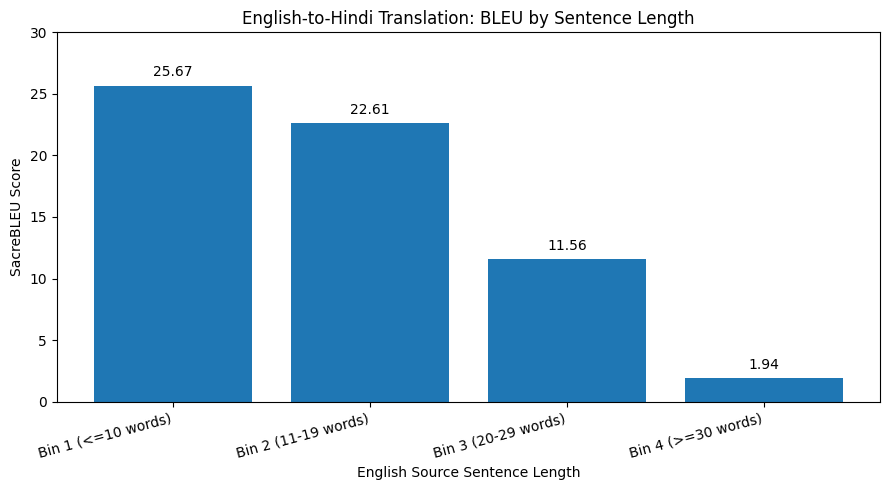

Chart saved to: /kaggle/working/opennmt_model/bleu_by_sentence_length.png


In [ ]:

import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/opennmt_model")

# Exclude overall BLEU so the chart compares the four length bins.
length_results = results.iloc[1:]

plt.figure(figsize=(9, 5))
bars = plt.bar(
    length_results["Test Subset"],
    length_results["SacreBLEU"]
)

plt.title("English-to-Hindi Translation: BLEU by Sentence Length")
plt.xlabel("English Source Sentence Length")
plt.ylabel("SacreBLEU Score")
plt.ylim(0, 30)
plt.xticks(rotation=15, ha="right")

for bar, score in zip(bars, length_results["SacreBLEU"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{score:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

chart_path = OUTPUT_DIR / "bleu_by_sentence_length.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


In [ ]:

summary = """English-to-Hindi Neural Machine Translation Evaluation

Model: OpenNMT Transformer
Training steps: 10,000
Held-out test sentences: 19,248

Overall SacreBLEU: 18.85

Length-wise SacreBLEU:
- Bin 1 (<=10 words): 25.67 (2,675 sentences)
- Bin 2 (11-19 words): 22.61 (11,896 sentences)
- Bin 3 (20-29 words): 11.56 (4,540 sentences)
- Bin 4 (>=30 words): 1.94 (137 sentences)

Observation:
The highest BLEU score is for sentences containing 10 words or fewer.
BLEU decreases for longer sentences, suggesting that longer inputs
are more challenging for this trained translation model. The result
for sentences with 30 or more words should be interpreted cautiously
because this group contains only 137 test examples.
"""

summary_path = OUTPUT_DIR / "evaluation_summary.txt"
summary_path.write_text(summary, encoding="utf-8")

print(summary)
print("Summary saved to:", summary_path)


English-to-Hindi Neural Machine Translation Evaluation

Model: OpenNMT Transformer
Training steps: 10,000
Held-out test sentences: 19,248

Overall SacreBLEU: 18.85

Length-wise SacreBLEU:
- Bin 1 (<=10 words): 25.67 (2,675 sentences)
- Bin 2 (11-19 words): 22.61 (11,896 sentences)
- Bin 3 (20-29 words): 11.56 (4,540 sentences)
- Bin 4 (>=30 words): 1.94 (137 sentences)

Observation:
The highest BLEU score is for sentences containing 10 words or fewer.
BLEU decreases for longer sentences, suggesting that longer inputs
are more challenging for this trained translation model. The result
for sentences with 30 or more words should be interpreted cautiously
because this group contains only 137 test examples.

Summary saved to: /kaggle/working/opennmt_model/evaluation_summary.txt


In [ ]:

from pathlib import Path
import shutil
import os

WORKING_DIR = Path("/kaggle/working")
MODEL_DIR = WORKING_DIR / "opennmt_model"
DATA_DIR = WORKING_DIR / "bpcc_en_hi"

# Create a folder for final assignment results
FINAL_DIR = WORKING_DIR / "final_assignment_results"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# Copy evaluation outputs
files_to_save = [
    MODEL_DIR / "bleu_results.csv",
    MODEL_DIR / "bleu_by_sentence_length.png",
    MODEL_DIR / "evaluation_summary.txt",
    MODEL_DIR / "predictions.hi",
    MODEL_DIR / "en_hi_step_10000.pt",
    MODEL_DIR / "config.yaml",
]

for file_path in files_to_save:
    if file_path.exists():
        shutil.copy2(file_path, FINAL_DIR / file_path.name)
        print("Saved:", file_path.name)
    else:
        print("Not found, skipped:", file_path.name)

# Save the held-out test references and English inputs
for filename in ["test.en", "test.hi"]:
    source = DATA_DIR / filename
    if source.exists():
        shutil.copy2(source, FINAL_DIR / filename)
        print("Saved:", filename)

# Create a ZIP archive of the final results
zip_path = shutil.make_archive(
    str(WORKING_DIR / "final_assignment_results"),
    "zip",
    root_dir=FINAL_DIR
)

print("\nFinal folder:", FINAL_DIR)
print("ZIP archive:", zip_path)
print("\nFiles in final folder:")
for file_path in sorted(FINAL_DIR.iterdir()):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")


Saved: bleu_results.csv
Saved: bleu_by_sentence_length.png
Saved: evaluation_summary.txt
Saved: predictions.hi
Saved: en_hi_step_10000.pt
Saved: config.yaml
Saved: test.en
Saved: test.hi

Final folder: /kaggle/working/final_assignment_results
ZIP archive: /kaggle/working/final_assignment_results.zip

Files in final folder:
bleu_by_sentence_length.png: 137,293 bytes
bleu_results.csv: 192 bytes
config.yaml: 1,387 bytes
en_hi_step_10000.pt: 124,463,852 bytes
evaluation_summary.txt: 712 bytes
predictions.hi: 3,514,276 bytes
test.en: 1,836,010 bytes
test.hi: 4,555,920 bytes
